## Setup

In [199]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as mticker
import colorsys # define colors in HLS

import statsmodels.formula.api as smf
import statsmodels.api as sm

from scipy.stats import linregress

import warnings
import sys
import os

from IPython.display import display

import testis_model as tm

In [200]:
plot_settings = {
    'font.family': 'Arial',
    'font.size': 11,              # base font size
    'xtick.labelsize': 11,        # x-axis tick label size
    'ytick.labelsize': 11,        # y-axis tick label size
    'axes.labelsize': 11,         # axis label size
    'axes.titlesize': 11,         # title size
    'legend.fontsize': 11,        # legend font size
    'figure.titlesize': 11        # figure title size
}

small_label_settings = {
    'font.family': 'Arial',
    'font.size': 11,              # base font size
    'xtick.labelsize': 8,        # x-axis tick label size
    'ytick.labelsize': 8,        # y-axis tick label size
    'axes.labelsize': 11,         # axis label size
    'axes.titlesize': 11,         # title size
    'legend.fontsize': 11,        # legend font size
    'figure.titlesize': 11        # figure title size
}

plt.rcParams.update(plot_settings)

In [324]:
df = pd.read_csv('../model_simulations/all_clone_results.csv')

experimental_scenario = 'full_pipeline_trunc'

invalid_real_entries = df.query('scenario == @experimental_scenario').query('max_time <= 5 or size == 1')
if len(invalid_real_entries) > 0:
    print(f'There are {len(invalid_real_entries)} real clones that have max_time <= 5 or size == 1.')

# Only include data that has at least 2 observations and are not trivial.
df = df.query('last_time > 5 and size < 1').copy()

print(f'The loaded clone data has {len(df)} rows.')

There are 2 real clones that have max_time <= 5 or size == 1.
The loaded clone data has 42572 rows.


In [325]:
def symlog10(x, linthresh=1e-2):
    # symmetric log transform in base 10
    return np.sign(x) * np.log10(1 + np.abs(x) / linthresh)

def inv_symlog10(y, linthresh=1e-2):
    # inverse of base-10 symlog
    return np.sign(y) * ((10**np.abs(y) - 1) * linthresh)

In [346]:
df['l_gap'] = df['l_max'] - df['l_null']
df['pass_null'] = df['l_gap'] > 2

with np.errstate(divide='ignore', invalid='ignore'):
    df['log_r'] = np.log(df['r_opt'])
    df['log10_r'] = np.log10(df['r_opt'])
df['symlog_r'] = symlog10(df['r_opt'])

df.head()

,scenario,fish,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,size,...,r_opt,l_max,lower,upper,l_null,l_gap,pass_null,log_r,symlog_r,log10_r
0,n1000_r10_y6,0,0,5.0,0.307278,20.0,5.0,20.0,0.420485,0.313894,...,9.502927,-54.590756,3.270517,30.590637,-138.671614,84.080858,True,2.251600,2.978314,0.977857
1,n1000_r10_y6,0,1,5.0,0.261456,20.0,5.0,20.0,0.164420,0.223965,...,9.091371,-53.211698,3.057740,28.737771,-78.480982,25.269284,True,2.207326,2.959107,0.958629
2,n1000_r10_y6,0,2,5.0,0.153639,16.0,5.0,20.0,0.000000,0.070081,...,14.125175,-37.272727,5.949853,37.629256,-174.208461,136.935734,True,2.647959,3.150301,1.149994
3,n1000_r10_y6,0,3,5.0,0.150943,20.0,5.0,20.0,0.212938,0.211223,...,10.296517,-53.669315,3.844471,30.870711,-88.089340,34.420025,True,2.331806,3.013112,1.012690
4,n1000_r10_y6,0,4,5.0,0.086253,20.0,5.0,20.0,0.202156,0.148493,...,6.230935,-50.982342,1.493676,21.424083,-61.326150,10.343808,True,1.829526,2.795250,0.794553


In [327]:
failed_converge = df[df['l_max'] < -1e5]
if len(failed_converge) > 0:
    print('The following rows did not have a convergent likelihood calculation:')
    display(failed_converge)   # explicitly display the DataFrame
else:
    print('All likelihood calculations converged successfully.')

The following rows did not have a convergent likelihood calculation:


,scenario,fish,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,size,avg_freq_change,r_opt,l_max,lower,upper,l_null,l_gap,pass_null,log_r,symlog_r
118,n1000_r10_y6,15,7,6.0,0.008086,6.0,5.0,20.0,0.00000,0.000735,NaN,2.717391,-1000000.0,0.0,NaN,-15.629979,-999984.370021,False,0.999672,2.435747
4165,n1000_r1.5_y6,14,8,6.0,0.002695,6.0,5.0,20.0,0.00000,0.000245,NaN,0.900901,-1000000.0,0.0,NaN,-11.948459,-999988.051541,False,-0.104360,1.959471
4166,n1000_r1.5_y6,14,9,6.0,0.002695,6.0,5.0,20.0,0.00000,0.000245,NaN,0.900901,-1000000.0,0.0,NaN,-11.948459,-999988.051541,False,-0.104360,1.959471
4404,n1000_r1.5_y6,40,8,6.0,0.010782,20.0,5.0,20.0,0.02965,0.021563,-0.001348,3.218076,-1000000.0,0.0,NaN,-39.709941,-999960.290059,False,1.168784,2.508944
4471,n1000_r1.5_y6,47,9,9.0,0.002695,14.0,5.0,20.0,0.00000,0.001715,0.000000,0.862007,-1000000.0,0.0,NaN,-17.963798,-999982.036202,False,-0.148492,1.940520
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24191,n1000_r2_y6,78,9,6.0,0.008086,6.0,5.0,20.0,0.00000,0.000735,NaN,2.717391,-1000000.0,0.0,NaN,-15.629979,-999984.370021,False,0.999672,2.435747
24282,n1000_r2_y6,88,8,6.0,0.002695,6.0,5.0,20.0,0.00000,0.000245,NaN,0.900901,-1000000.0,0.0,NaN,-11.948459,-999988.051541,False,-0.104360,1.959471
26281,n1000_r6_y6,38,6,6.0,0.002695,16.0,5.0,20.0,0.00000,0.010782,-0.000809,7.245379,-1000000.0,0.0,NaN,-49.307798,-999950.692202,False,1.980364,2.860660
26313,n1000_r6_y6,42,7,6.0,0.013477,6.0,5.0,20.0,0.00000,0.001225,NaN,4.553734,-1000000.0,0.0,NaN,-20.280466,-999979.719534,False,1.515948,2.659320


In [328]:
def hue(r):
    lamb = (symlog10(r) - symlog10(0)) / (symlog10(36) - symlog10(0))
    return colorsys.hls_to_rgb(0.5, 0.30 + 0.45 * lamb, 0.5)

experimental_hue = '#ffc566'

## Quantify model prediction bias

In [329]:
r_values = [0, 1, 4, 15, 36]
for r in r_values:
    scenario = f'n1000_r{r}_y6'
    r_opts = df.query(f'scenario == @scenario')['r_opt']
    print(f'r = {r}:\t{np.mean(r_opts):.2f}\t+/- {np.std(r_opts)/np.sqrt(len(r_opts)):.2f}')

r = 0:	0.05	+/- 0.01
r = 1:	1.00	+/- 0.03
r = 4:	3.82	+/- 0.08
r = 15:	13.26	+/- 0.29
r = 36:	29.11	+/- 0.89


## Workspace

## Panel 5a

In [330]:
# Define mapping from scenario string to numeric r
scenario_map = {
    'n1000_r1_y6': 'Model\n$rp=1$',
    'n1000_r4_y6': 'Model\n$rp=4$',
    'n1000_r15_y6': 'Model\n$rp=15$',
    'n1000_r36_y6': 'Model\n$rp=36$',
    experimental_scenario: 'Exp. data'
}

df_plot = df.query('scenario.isin(@scenario_map.keys())').copy()
df_plot = df_plot.query('(scenario == @experimental_scenario) | (fish < 24)').copy()
df_plot['scenario_label'] = df_plot['scenario'].map(scenario_map)

palette = {
    'Model\n$rp=1$': hue(1),
    'Model\n$rp=4$': hue(4),
    'Model\n$rp=15$': hue(15),
    'Model\n$rp=36$': hue(36),
    'Exp. data': experimental_hue
}

order = ['Model\n$rp=1$', 'Model\n$rp=4$', 'Model\n$rp=15$', 'Model\n$rp=36$', 'Exp. data']

zero_counts = df_plot.groupby('scenario')['r_opt'].apply(lambda x: (x==0).mean()*100)

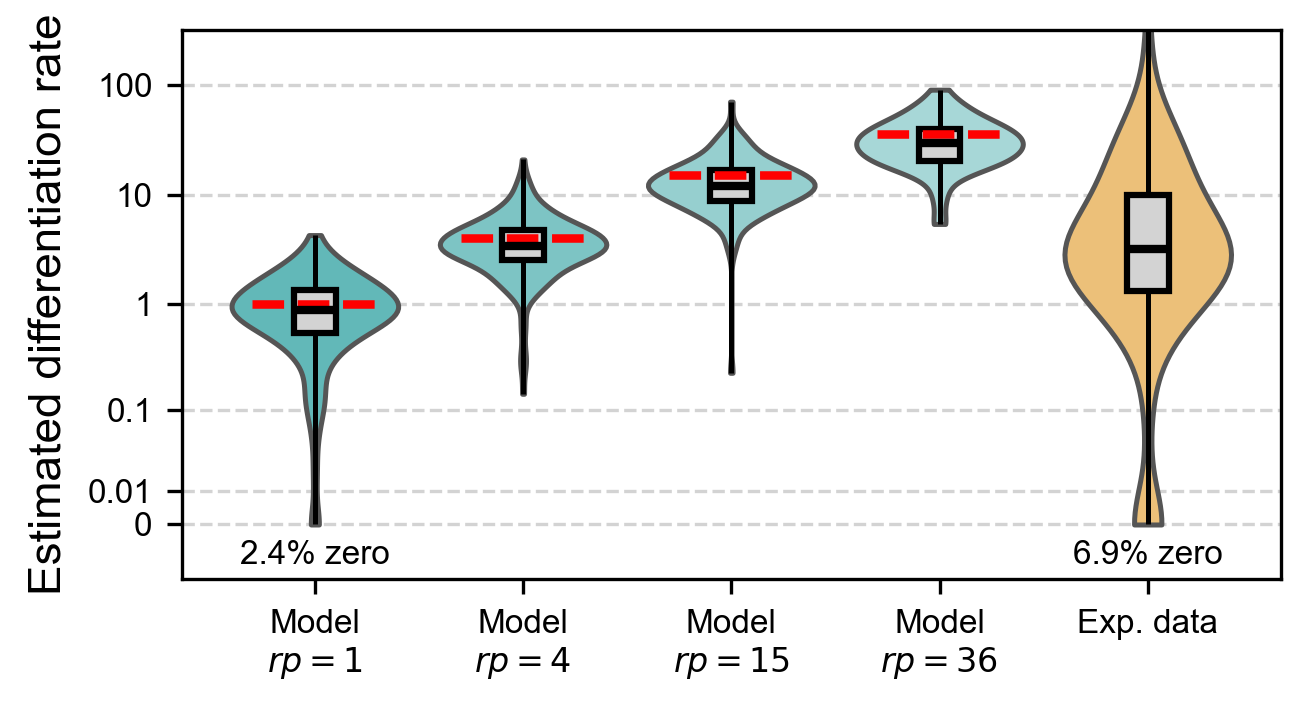

In [331]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(figsize = (4.5, 2.5), dpi = 300)    

sns.violinplot(
    data=df_plot, x='scenario_label', y='symlog_r',
    order=order,
    inner=None, cut=0, hue='scenario_label',
    density_norm='area', linewidth=1.2, palette=palette, ax=ax, legend=False
)

sns.boxplot(
    data=df_plot, x='scenario_label', y='symlog_r',
    order=order,
    whis=np.inf, width=0.2, showcaps=False,
    boxprops={'facecolor':'lightgray', 'edgecolor':'black', 'linewidth':1.5},
    whiskerprops={'color':'black', 'linewidth':1.2},
    capprops={'color':'black', 'linewidth':1.2},
    medianprops={'color':'black', 'linewidth':2},
    ax=ax
)

# "True" r values in red dashed lines
for i, r in enumerate([1, 4, 15, 36]):
    ax.hlines(
        y=symlog10(r, linthresh=1e-2), xmin=i-0.3, xmax=i+0.3,
        colors='red', linestyles='dashed', linewidth=2.05
    )

# Annotations with pertentage of clones that are zero.
pct = zero_counts.get('n1000_r1_y6', 0)
ax.text(0, ax.get_ylim()[0]/2, f"{pct:.1f}% zero",
        ha='center', va='top', fontsize=8)

pct = zero_counts.get(experimental_scenario, 0)
ax.text(4, ax.get_ylim()[0]/2, f"{pct:.1f}% zero",
        ha='center', va='top', fontsize=8)

ax.set_xlabel('')

# Set y ticks.
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax.set_yticks(tick_symlog)
ax.set_yticklabels([str(r) for r in tick_r])
ax.set_ylim([-0.5, 4.5])
ax.set_ylabel('Estimated differentiation rate')

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')
ax.set_axisbelow(True) 

plt.tight_layout()
plt.savefig('./images/violin.svg', bbox_inches = 'tight', pad_inches = 0)

## Panel 5b

In [332]:
def make_summary(df):
    summary = (
        df.groupby("fish")["symlog_r"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    summary["se"] = summary["std"] / summary["count"]**0.5
    summary["ci_low"] = summary["mean"] - 1.96 * summary["se"]
    summary["ci_high"] = summary["mean"] + 1.96 * summary["se"]
    return summary.sort_values("mean")

# Filter scenarios
df_full = df_plot.query('scenario == @experimental_scenario')
df_sim  = df_plot.query('scenario == "n1000_r4_y6"')

summary_full = make_summary(df_full)
summary_sim  = make_summary(df_sim)

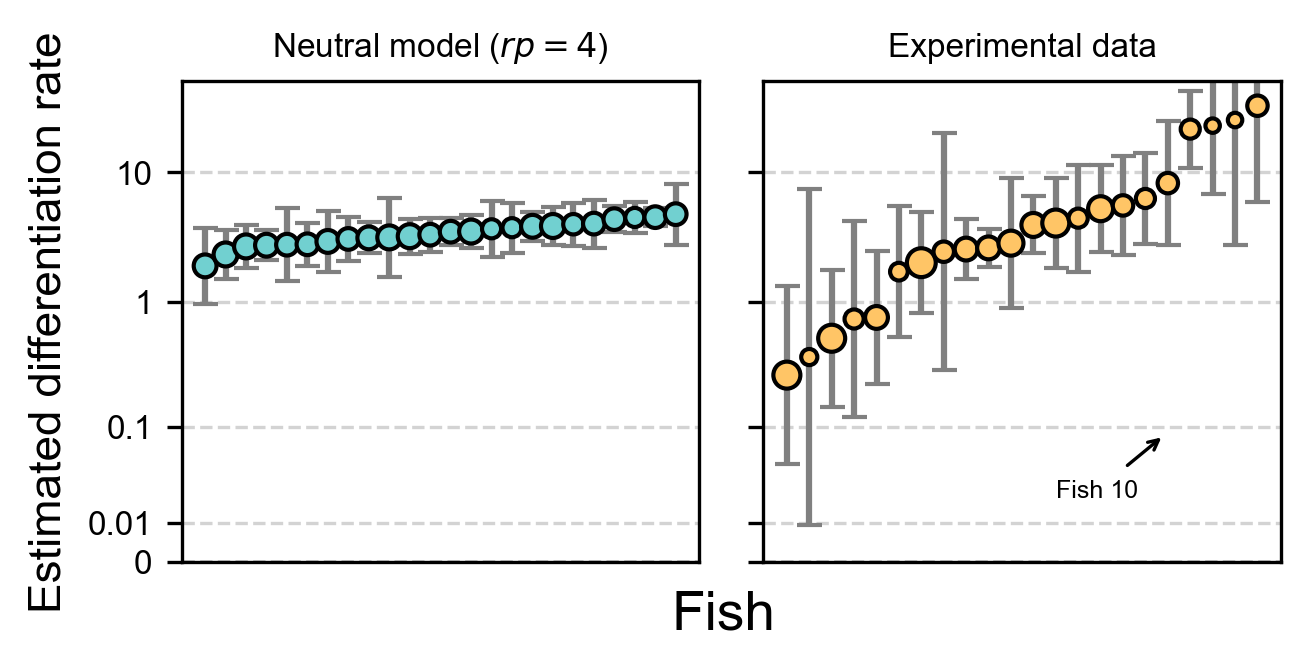

In [333]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, axes = plt.subplots(1, 2, figsize=(4.5, 2.5), dpi=300, sharey=True)

for ax, summary, title, color in zip(
    axes,
    [summary_sim, summary_full],
    ["Neutral model ($rp=4$)", "Experimental data"],
    [hue(4), experimental_hue]
):
    xpos = range(len(summary))

    # Plot error bars (without markers)
    ax.errorbar(
        xpos, summary["mean"],
        yerr=[summary["mean"] - summary["ci_low"], summary["ci_high"] - summary["mean"]],
        fmt="none", ecolor="gray", capsize=3
    )

    # Overlay scatter points with size proportional to count
    sizes = summary["count"] * 3   # scale factor, adjust as needed
    ax.scatter(
        xpos, summary["mean"],
        s=sizes, facecolor=color, edgecolor="black", zorder=3
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(title, fontsize=8)
    # ax.set_xlabel('')
    # ax.set_xticks(xpos)
    # ax.set_xticklabels(summary["fish"], size=6, rotation=90)
    ax.set_xticks([])
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')

# Shared y-axis formatting
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
axes[0].set_ylabel("Estimated differentiation rate")
for ax in axes:
    ax.set_yticks(tick_symlog)
    ax.set_yticklabels([str(r) for r in tick_r])
    ax.set_ylim([0, 3.7])

axes[1].annotate(
    'Fish 10', xy=(17, 1.0), xytext=(12, 0.5), fontsize=6,
    arrowprops=dict(arrowstyle="->", color="black", lw=0.8)
)

fig.supxlabel("Fish", x=0.55, y = 0.12)

plt.tight_layout()
plt.savefig('./images/anova.svg', bbox_inches = 'tight', pad_inches = 0)

In [334]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp, levene

# Subset the data
group1 = df_plot.loc[df_plot['scenario'] == experimental_scenario, 'log_r']
group2 = df_plot.loc[df_plot['scenario'] == 'n1000_r4_y6', 'log_r']

# Remove NaNs and -inf
group1 = group1[~group1.isna() & (group1 != -np.inf)]
group2 = group2[~group2.isna() & (group2 != -np.inf)]

# Kolmogorov–Smirnov test (two-sample)
ks_stat, ks_pval = ks_2samp(group1, group2)

# Levene’s test (variance comparison, robust to non-normality)
lev_stat, lev_pval = levene(group1, group2)

# Variances
var1 = group1.var(ddof=1)  # sample variance
var2 = group2.var(ddof=1)

print("Kolmogorov–Smirnov test:")
print(f"  Statistic = {ks_stat:.4f}, p-value = {ks_pval:.4g}")

print("\nLevene’s test for equal variances:")
print(f"  Statistic = {lev_stat:.4f}, p-value = {lev_pval:.4g}")

print("\nSample variances:")
print(f"  Group1 variance = {var1:.4f}")
print(f"  Group2 variance = {var2:.4f}")

Kolmogorov–Smirnov test:
  Statistic = 0.2412, p-value = 9.505e-06

Levene’s test for equal variances:
  Statistic = 27.3291, p-value = 2.734e-07

Sample variances:
  Group1 variance = 7.6446
  Group2 variance = 0.4483


In [74]:
import pandas as pd
import numpy as np

# Subset to scenario == "real"
group2 = df.loc[(df['scenario'] == 'full_pipeline') & (df['r_opt'] > 0), ['r_opt', 'fish']]
# group2 = df.loc[(df['scenario'] == 'real') & (df['r_median'] > 0), ['r_median', 'fish']]
group2['log_r'] = np.log(group2['r_opt'])

# Overall mean
grand_mean = group2['log_r'].mean()

# Group means and sizes
group_stats = group2.groupby('fish')['log_r'].agg(['mean', 'count'])

# --- Between-group variance ---
# Weighted variance of group means around the grand mean
between_var = (group_stats['count'] * (group_stats['mean'] - grand_mean)**2).sum() / (group_stats['count'].sum() - 1)

# --- Within-group variance ---
# Pooled variance across groups
within_var = group2.groupby('fish').apply(lambda g: g['log_r'].var(ddof=1) * (len(g)-1), include_groups = False).sum() / (len(group2) - len(group_stats))

print("Between-group variance:", between_var)
print("Within-group variance:", within_var)

Between-group variance: 1.2198654590113185
Within-group variance: 6.906444565266333


In [82]:
df_anova = df.query('scenario.isin(["full_pipeline", "n1000_r4_y6"])').copy()
# df_anova['log_r'] = df_anova['r_opt']
df_anova['symlog_r'] = symlog10(df_anova['r_opt'])

In [83]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Assume df has columns: scenario, fish, log_r

# Treat fish as nested within scenario
df_anova['scenario'] = df['scenario'].astype('category')
df_anova['fish'] = df['fish'].astype('category')

# Build model: log_r ~ scenario + fish(scenario)
# In statsmodels, nesting is written as C(fish):C(scenario)
model = ols('symlog_r ~ C(scenario) + C(fish):C(scenario)', data=df_anova).fit()

anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 47, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J


KeyboardInterrupt: 

In [76]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols('log_r ~ C(fish)', data=group2).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

               sum_sq     df         F    PR(>F)
C(fish)    323.264347   23.0  2.035052  0.004443
Residual  1671.359585  242.0       NaN       NaN


## Panel 4d

In [336]:
scenarios = ['n1000_r0_y6', 'n1000_r1_y6', experimental_scenario]
scenarios_labels = ['Model\n$rp=0$', 'Model\n$rp=1$', 'Exp. data']
mapping = dict(zip(scenarios, scenarios_labels))

df2 = df.query('scenario.isin(@scenarios)').copy()
df2['scenario'] = df2['scenario'].map(mapping)
agg_df = df2.groupby('scenario', as_index=False).agg({'pass_null': 'mean'})
agg_df['percent_pass'] = agg_df['pass_null'] * 100
agg_df

,scenario,pass_null,percent_pass
0,Exp. data,0.683168,68.316832
1,Model\n$rp=0$,0.016000,1.600000
2,Model\n$rp=1$,0.843750,84.375000


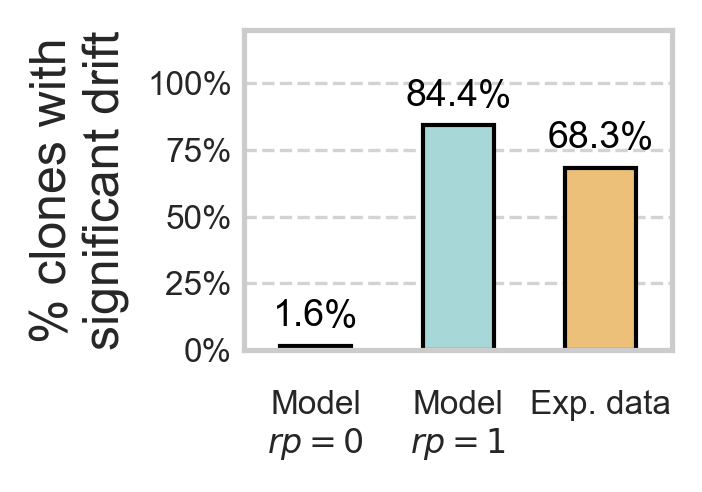

In [337]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(2.5, 1.8), dpi=300)

palette = {
    'Model\n$rp=0$': hues[0],
    'Model\n$rp=1$': hues[1],
    'Exp. data': '#ffc566'
}

ax = sns.barplot(
    data=agg_df, x='scenario', y='percent_pass',
    edgecolor='black', hue='scenario', palette=palette, legend=False,
    width = 0.5, order = ['Model\n$rp=0$', 'Model\n$rp=1$', 'Exp. data']
)

# Grid styling
ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis = 'y')

plt.ylabel("% clones with\nsignificant drift", fontsize=12)
plt.xlabel('')
plt.xticks(rotation=0, ha='center', fontsize=8)
# plt.title("% with significant evidence of drift", fontsize=13)

# Annotate values above bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.1f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=9, color='black', xytext=(0, 3),
                textcoords='offset points')

ax.set_ylim(0, 120)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.tick_params(axis='y', labelsize=8, pad=-3)
ax.set_yticks([0, 25, 50, 75, 100])

plt.tight_layout()
plt.savefig('./images/null_hypothesis.svg', bbox_inches = 'tight', pad_inches = 0)

## Panel 4e

In [338]:
df2 = df.query('scenario == @experimental_scenario').copy()
df2.head()

import statsmodels.api as sm

# Ensure pass_null is numeric (0/1)
df2['pass_null'] = df2['pass_null'].astype(int)

# Define predictor and response
X = sm.add_constant(df2['last_time'])   # adds intercept
y = df2['pass_null']

# Fit logistic regression
model = sm.Logit(y, X).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.608350
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              pass_null   No. Observations:                  202
Model:                          Logit   Df Residuals:                      200
Method:                           MLE   Df Model:                            1
Date:                Tue, 09 Dec 2025   Pseudo R-squ.:                 0.02580
Time:                        09:38:23   Log-Likelihood:                -122.89
converged:                       True   LL-Null:                       -126.14
Covariance Type:            nonrobust   LLR p-value:                   0.01074
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2630      0.432     -0.608      0.543      -1.110       0.584
last_time      0.0674      0.

In [339]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a grid of last_time values across the observed range
x_vals = np.linspace(4, 28, 200)
X_pred = sm.add_constant(x_vals)

# Predicted probabilities from the logistic model
y_pred = model.predict(X_pred)

# --- Compute confidence intervals ---
# Get covariance matrix of parameters
cov = model.cov_params()
params = model.params.values

# Linear predictor and its variance
lin_pred = X_pred @ params
var_lin_pred = np.sum((X_pred @ cov) * X_pred, axis=1)
se_lin_pred = np.sqrt(var_lin_pred)

# 95% CI on logit scale, then transform back to probability
logit_lower = lin_pred - 1.96 * se_lin_pred
logit_upper = lin_pred + 1.96 * se_lin_pred
ci_lower = 1 / (1 + np.exp(-logit_lower))
ci_upper = 1 / (1 + np.exp(-logit_upper))

4 16


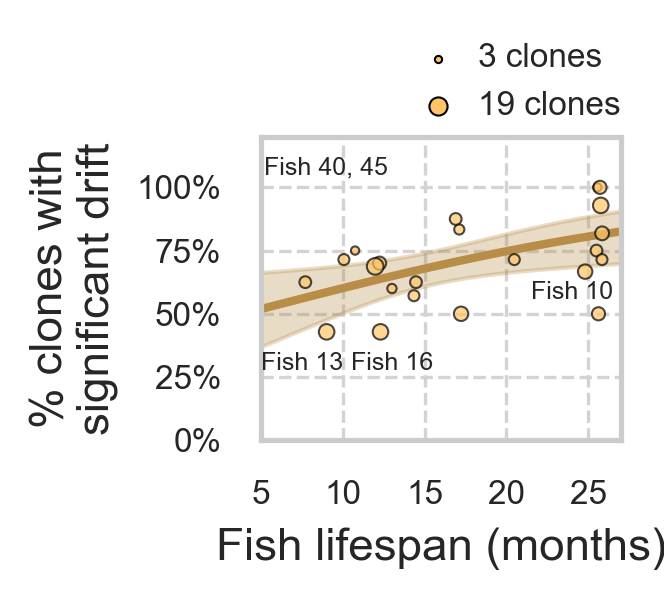

In [340]:
plt.rcParams.update(plot_settings)
fig, ax = plt.subplots(figsize = (2.3, 2.1), dpi = 300)

agg = df2.groupby(['fish']).agg({'pass_null': 'mean', 'max_time': 'first', 'clone': 'count'})
agg['pass_null'] = agg['pass_null'] * 100
print(agg['clone'].min(), agg['clone'].max())

rng = np.random.default_rng()
x_jittered = agg['max_time'] + rng.uniform(-0.25, 0.25, size=len(agg))
ax.scatter(x_jittered, agg['pass_null'], color = '#ffc566',
    edgecolors='black',       # stroke color
    linewidths=0.5,           # stroke thickness
     zorder=5,
    s = agg['clone'],
          alpha = 0.7)
# Logistic fit
ax.plot(x_vals, 100*y_pred, color="#b88d48", linewidth=2, label="Logit fit")

# Confidence interval band
ax.fill_between(x_vals, 100*ci_lower, 100*ci_upper, color="#b88d48", alpha=0.3, label="95% CI")
ax.set_xlabel('Fish lifespan (months)')
ax.set_ylabel('% clones with\nsignificant drift')

ax.set_ylim(0, 120)
ax.set_xlim(5, 27)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.tick_params(axis='y', labelsize=8)
ax.tick_params(axis='x', labelsize=8)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xticks([5, 10, 15, 20, 25])

# Custom legend handles as before
sizes = [3, 19]
legend_handles = [
    plt.scatter([], [], s=size, color='#ffc566',
                edgecolors='black', linewidths=0.5)
    for size in sizes
]

leg = ax.legend(
    legend_handles,
    [f"{size} clones" for size in sizes],
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.7, 0.95),  # adjust horizontal position
    ncol=1,
    fontsize=8,
    handletextpad=0.2
)

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')

ax.text(13, 28, 'Fish 16', fontsize=6, ha='center')
ax.text(7.5, 28, 'Fish 13', fontsize=6, ha='center')
ax.text(24, 56, 'Fish 10', fontsize=6, ha='center')
ax.text(9, 105, 'Fish 40, 45', fontsize=6, ha='center')

plt.tight_layout()
plt.savefig('images/lifespan_null.svg', bbox_inches = 'tight', pad_inches = 0)

## Panel 4c

In [341]:
model_simulations_path = os.path.abspath("../model_simulations")

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)

print("Added to path:", model_simulations_path)
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios('full_pipeline', directory = scenarios_directory)

Added to path: /Users/connor/Documents/github/sperm-data-analysis/model_simulations


In [71]:
f = 1
df.query('fish == @f and scenario == "full_pipeline"')[['clone', 'r_median', 'l_gap']]

,clone,r_median,l_gap
27828,0,16.746456,3946.234232
27829,1,23.312254,887.168969
27830,2,3.375175,98.707760
27831,3,13.974469,78.871570
27832,4,3.651119,37.018785
27833,5,2.905457,24.517689
27834,6,2.920352,15.886042
27835,7,2.095218,109.277700
27836,8,1.615945,14.244396
27837,9,0.827664,10.988719


In [67]:
plt.style.use('default')
fig4c_settings = {
    'font.family': 'Arial',
    'font.size': 11,              # base font size
    'xtick.labelsize': 8,        # x-axis tick label size
    'ytick.labelsize': 8,        # y-axis tick label size
    'axes.labelsize': 11,         # axis label size
    'axes.titlesize': 11,         # title size
    'legend.fontsize': 11,        # legend font size
    'figure.titlesize': 11        # figure title size
}
plt.rcParams.update(fig4c_settings)

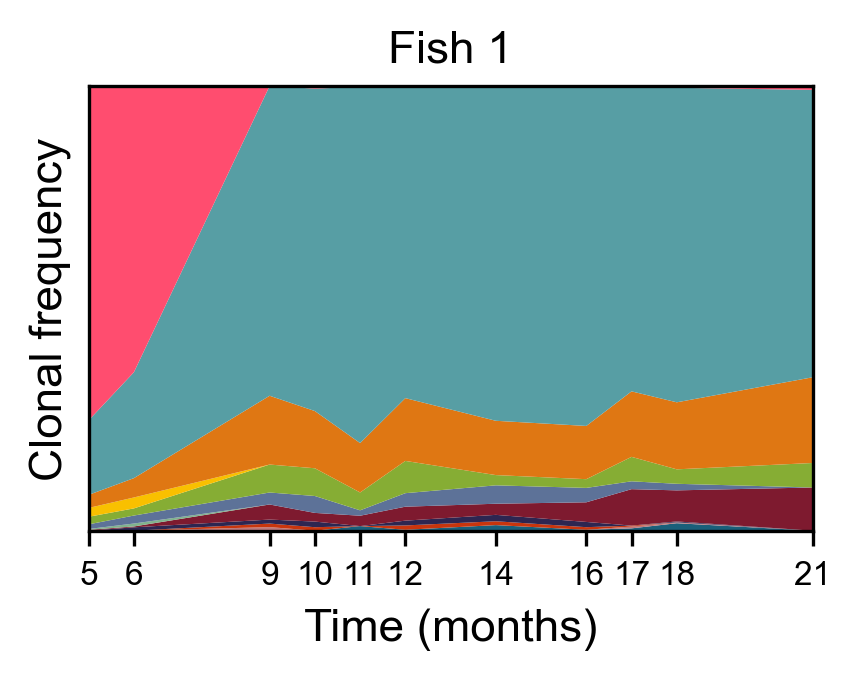

In [69]:
fig, ax = plt.subplots(figsize = (3, 2.4), dpi=300)
tm.visualize.plot(fish_data['full_pipeline', f], ax = ax)
ax.set_yticks([])
ax.set_xlabel('Time (months)')
ax.set_title('Fish 1')

plt.tight_layout()
plt.savefig('images/fish1.svg', bbox_inches = 'tight', pad_inches = 0)

In [200]:
scenario = "real"
real_df = df.query('scenario == @scenario')
num_real = len(real_df)
prop_drift = real_df['pass_null'].mean()
print(f'Of the {num_real} experimental clones, {100*prop_drift:.1f}% show significant evidence of drifting.')

Of the 262 experimental clones, 83.6% show significant evidence of drifting.


## Dependence on initial frequency

In [178]:
# Subset to only the "real" scenario
df_real = df.query('scenario == "real" and ~r_median.isna()').copy()

# Make sure pass_null is numeric (0/1)
df_real["pass_null"] = df_real["pass_null"].astype(int)

# Logistic regression: pass_null ~ init_freq
logit_model_real = smf.logit("pass_null ~ init_freq", data=df_real).fit()

print(logit_model_real.summary())
print(logit_model_real.pvalues)

Optimization terminated successfully.
         Current function value: 0.437944
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              pass_null   No. Observations:                  259
Model:                          Logit   Df Residuals:                      257
Method:                           MLE   Df Model:                            1
Date:                Mon, 24 Nov 2025   Pseudo R-squ.:                 0.02576
Time:                        10:11:55   Log-Likelihood:                -113.43
converged:                       True   LL-Null:                       -116.43
Covariance Type:            nonrobust   LLR p-value:                   0.01432
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.3432      0.199      6.754      0.000       0.953       1.733
init_freq      4.0535      2.

In [179]:
x_vals = np.linspace(df_real['init_freq'].min(),
                     df_real['init_freq'].max(),
                     200)   # 200 evenly spaced points

# Build a dataframe for prediction
pred_df = pd.DataFrame({'init_freq': x_vals})

# Get predicted probabilities
pred_summary = logit_model_real.get_prediction(pred_df).summary_frame()

# This gives columns: mean, mean_ci_lower, mean_ci_upper
# Rename for clarity
pred_summary = pred_summary.rename(columns={
    'mean': 'predicted',
    'mean_ci_lower': 'ci_lower',
    'mean_ci_upper': 'ci_upper'
})

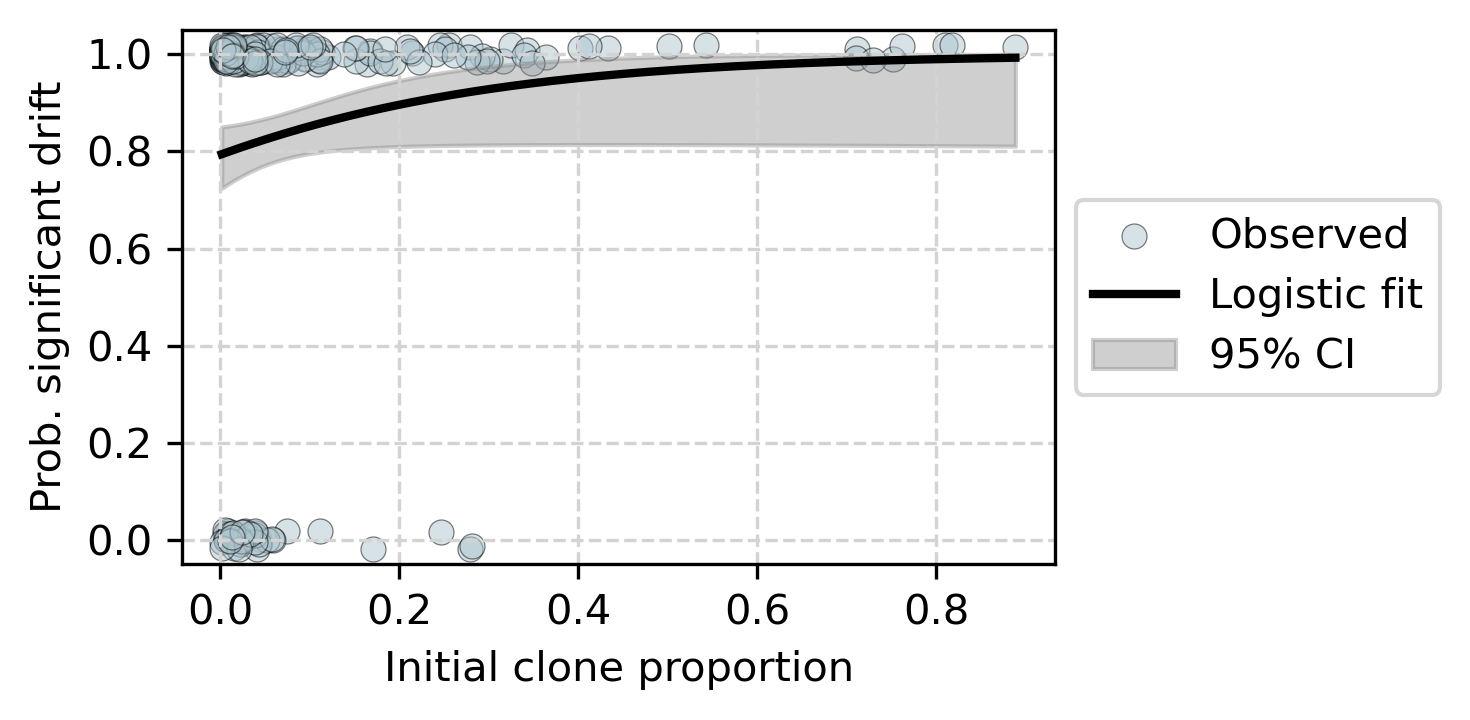

In [180]:
# Plot observed data (jittered vertically for clarity)
plt.figure(figsize=(5,2.5), dpi=300)

plt.scatter(df_real['init_freq'],
            df_real['pass_null'] + np.random.uniform(-0.02,0.02,len(df_real)),
            alpha=0.5, color="#AEC6CF", edgecolor="black", linewidth=0.3,
            label="Observed")

# Plot logistic curve
plt.plot(x_vals, pred_summary['predicted'], color="black", linewidth=2, label="Logistic fit")

# Add confidence/error bands with a different color
plt.fill_between(x_vals,
                 pred_summary['ci_lower'],
                 pred_summary['ci_upper'],
                 color="#888888", alpha=0.4, label="95% CI")  # peach color

# Labels and styling
plt.xlabel("Initial clone proportion")
plt.ylabel("Prob. significant drift")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle="--", linewidth=0.8, color="lightgray")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

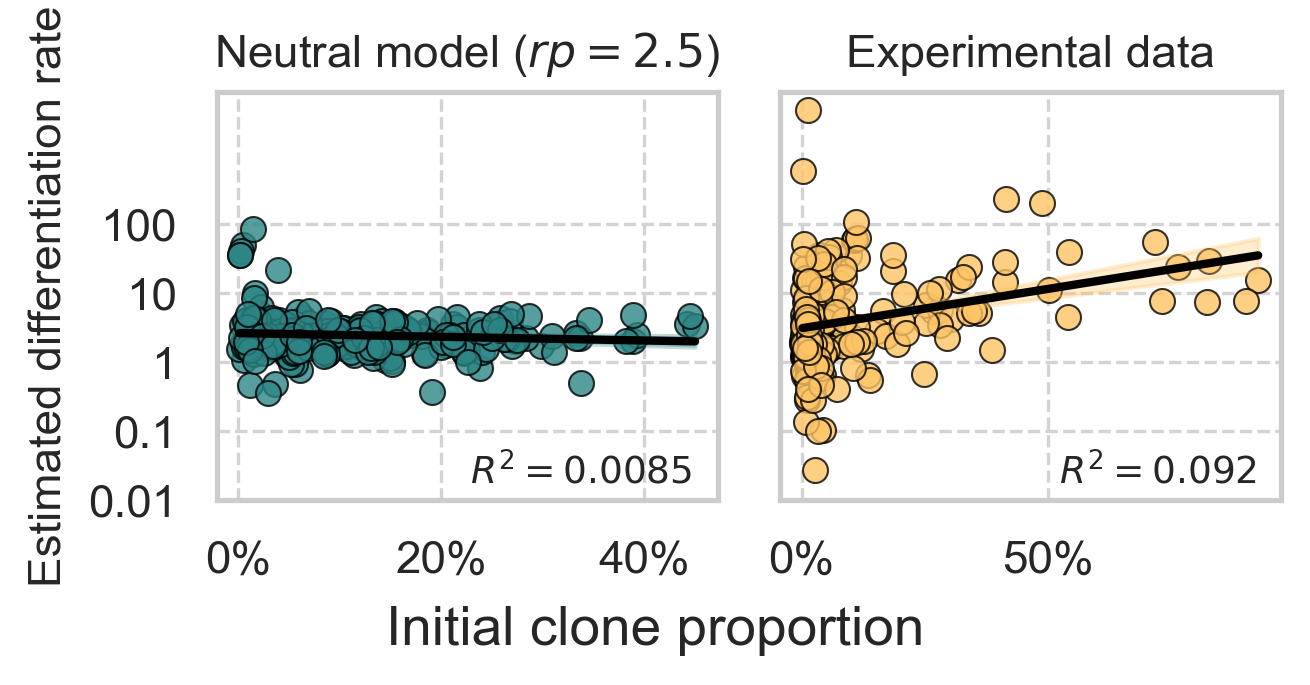

In [348]:
# Subset
compare_sim = "n1000_r2.5_y6"
real = df.query('scenario == @experimental_scenario and ~r_opt.isna() and r_opt > 1e-8').copy()
sim  = df.query('scenario == @compare_sim and ~r_opt.isna() and r_opt > 0 and fish < 30').copy()

# Fit regressions
slope_real, intercept_real, r_real, p_real, stderr_real = linregress(real['init_freq'], real['log10_r'])
slope_sim, intercept_sim, r_sim, p_sim, stderr_sim = linregress(sim['init_freq'], sim['log10_r'])

# Pastel palette
pastel_blue   = hues[0]  # soft blue
pastel_orange = '#ffc566'  # peach
line_color    = '#000000'  # muted gray for regression lines


palette = {
    'Model\n$rp=0$': hues[0],
    'Model\n$rp=1$': hues[1],
    'Exp. data': '#ffc566'
}

# X values for smooth line
x_real = np.linspace(real['init_freq'].min(), real['init_freq'].max(), 200)
x_sim  = np.linspace(sim['init_freq'].min(), sim['init_freq'].max(), 200)

# Predicted values
y_real = intercept_real + slope_real * x_real
y_sim  = intercept_sim + slope_sim * x_sim

# Error regions (±1 stderr on slope, approximate)
y_real_upper = intercept_real + (slope_real + stderr_real) * x_real
y_real_lower = intercept_real + (slope_real - stderr_real) * x_real

y_sim_upper = intercept_sim + (slope_sim + stderr_sim) * x_sim
y_sim_lower = intercept_sim + (slope_sim - stderr_sim) * x_sim

# Plot
fig, axes = plt.subplots(1, 2, figsize=(4.5,2.5), dpi=300, sharey=True)

# Grid styling
for ax in axes:
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax.set_axisbelow(True) 

# Sim scenario
axes[0].scatter(sim['init_freq'], sim['log10_r'], color=pastel_blue, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[0].plot(x_sim, y_sim, color=line_color, linewidth=2)
axes[0].fill_between(x_sim, y_sim_lower, y_sim_upper, color=pastel_blue, alpha=0.3)
axes[0].set_title("Neutral model ($rp=2.5$)")
axes[0].set_ylabel("Estimated differentiation rate")

# Real scenario
axes[1].scatter(real['init_freq'], real['log10_r'], color=pastel_orange, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[1].plot(x_real, y_real, color=line_color, linewidth=2)
axes[1].fill_between(x_real, y_real_lower, y_real_upper, color=pastel_orange, alpha=0.3)
axes[1].set_title(f"Experimental data")

# Y-axis ticks
yticks = np.arange(-2, 3)   # gives 10^-2 through 10^2
axes[0].set_yticks(yticks)
axes[0].set_yticklabels([0.01, 0.1, 1, 10, 100])

axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

fig.supxlabel("Initial clone proportion", y=0.1)

# Annotate R^2 values at bottom right of each axis
axes[0].text(0.95, 0.025, f"$R^2 = {r_sim**2:.4f}$",
             transform=axes[0].transAxes, ha='right', va='bottom', fontsize=9)
axes[1].text(0.95, 0.025, f"$R^2 = {r_real**2:.3f}$",
             transform=axes[1].transAxes, ha='right', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('./images/correlation.svg', bbox_inches = 'tight', pad_inches = 0)

In [353]:
sim[sim['log10_r'] > 1.5]

,scenario,fish,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,size,...,r_opt,l_max,lower,upper,l_null,l_gap,pass_null,log_r,symlog_r,log10_r
41139,n1000_r2.5_y6,14,9,5.0,0.004492,20.0,5.0,20.0,0.024259,0.050968,...,50.450079,-11.114239,1.316841,1099.715106,-35.099819,23.985580,True,3.920984,3.702948,1.702862
41147,n1000_r2.5_y6,15,7,5.0,0.014376,20.0,5.0,20.0,0.040431,0.047047,...,85.921336,-11.168671,5.246231,1166.314704,-59.803340,48.634669,True,4.453432,3.934152,1.934101
41167,n1000_r2.5_y6,17,8,5.0,0.002695,20.0,5.0,20.0,0.021563,0.016908,...,40.924435,-9.380142,0.640140,1081.460019,-30.620283,21.240140,True,3.711727,3.612089,1.611983
41222,n1000_r2.5_y6,23,8,5.0,0.001797,17.0,5.0,20.0,0.000000,0.012742,...,35.391388,-8.671136,0.369267,1070.871530,-28.933884,20.262748,True,3.566469,3.549020,1.548898
41233,n1000_r2.5_y6,24,9,5.0,0.001797,20.0,5.0,20.0,0.051213,0.033815,...,35.391702,-9.366982,0.369267,1070.871529,-29.629730,20.262748,True,3.566477,3.549024,1.548901


In [159]:
r_sim**2

np.float64(0.00016401982812824513)

In [154]:
real[real['log_r_opt'] < -1]['r_opt']

27857    7.231188e-02
27866    2.743545e-02
27954    8.081445e-02
27969    2.091060e-02
28023    9.030490e-03
28037    8.881784e-16
28042    3.037406e-03
28071    8.514500e-02
28072    4.909670e-02
Name: r_opt, dtype: float64

In [89]:
from scipy.stats import ecdf

In [96]:
data

27836     5.76
27837     8.86
27838     8.86
27839    11.00
27842    16.10
         ...  
28093     9.93
28094     9.93
28095     9.93
28096    12.10
28107     8.86
Name: init_time, Length: 140, dtype: float64

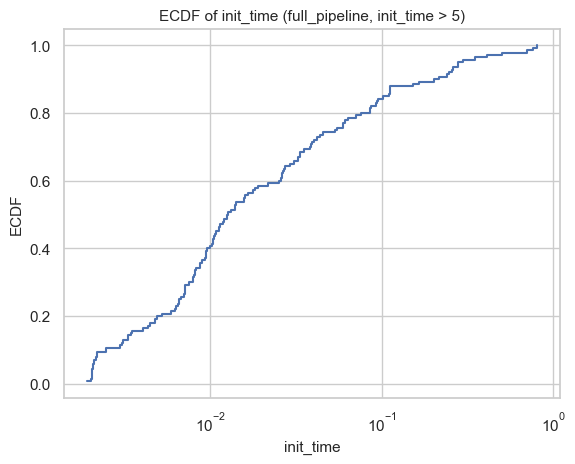

In [98]:
import numpy as np
import matplotlib.pyplot as plt

# Extract the data
data = df[(df['scenario'] == 'full_pipeline') & (df['init_time'] > 5)]['init_freq']

# Sort values
x = np.sort(data)
# Compute ECDF values
y = np.arange(1, len(x)+1) / len(x)

# Plot ECDF
fig, ax = plt.subplots()
ax.step(x, y, where='post')
ax.set_xlabel("init_time")
ax.set_ylabel("ECDF")
ax.set_title("ECDF of init_time (full_pipeline, init_time > 5)")

ax.set_xscale('log')
plt.show()

In [103]:
data = df[(df['scenario'] == 'full_pipeline') & (df['init_time'] > 5)].copy()
data[data['init_freq'] > 0.1]

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,r_opt,if_opt,l_max,lower,upper,if_null,l_null,l_gap,pass_null
27843,full_pipeline,12,0,8.86,0.256028,22.43,25.60,0.000000,0.088694,0.018660,4.983855,NaN,-120.669122,2.609616,10.488281,NaN,-845.650299,7.249812e+02,True
27844,full_pipeline,12,1,8.86,0.164179,22.43,25.60,0.000000,0.056572,0.011961,5.453109,NaN,-113.610687,2.641557,11.811055,NaN,-453.417474,3.398068e+02,True
27845,full_pipeline,12,2,8.86,0.152698,25.60,25.60,0.017914,0.056066,0.008052,2.818610,NaN,-125.333577,1.223388,7.105100,NaN,-314.995147,1.896616e+02,True
27848,full_pipeline,12,5,8.86,0.102181,22.43,25.60,0.000000,0.030773,0.007323,2.315371,NaN,-105.332023,1.039837,5.291029,NaN,-284.441502,1.791095e+02,True
27905,full_pipeline,16,0,8.86,0.280473,12.10,12.10,0.268873,0.275284,0.003580,5.361152,NaN,-48.528864,0.487198,44.424916,NaN,-51.836317,3.307453e+00,True
27906,full_pipeline,16,1,8.86,0.248521,12.10,12.10,0.266805,0.248242,-0.005643,0.669943,NaN,-47.373633,0.000000,8.734143,NaN,-48.968154,1.594521e+00,False
27907,full_pipeline,16,2,8.86,0.111243,12.10,12.10,0.186143,0.151163,-0.023117,3.120253,NaN,-44.675519,0.670447,25.284706,NaN,-58.503895,1.382838e+01,True
27937,full_pipeline,18,0,8.86,0.706897,25.60,25.60,0.260000,0.680449,0.026696,11.196377,NaN,-132.270875,4.947459,30.621426,NaN,-740.682056,6.084112e+02,True
27938,full_pipeline,18,1,8.86,0.215517,25.60,25.60,0.009091,0.142947,0.012331,2.801667,NaN,-104.394415,1.287932,6.833962,NaN,-305.652645,2.012582e+02,True
27948,full_pipeline,2,4,16.10,0.203349,23.60,24.70,0.000000,0.006875,0.024860,2.789410,NaN,-176.663285,2.359689,10.978809,NaN,-340.292352,1.636291e+02,True


In [185]:
df_hypothesis = df.query('~r_median.isna() and r_median > 0 and scenario in ["real", "n1000_r2.5_y6"]')
df_hypothesis = df_hypothesis[~((df_hypothesis['scenario'] == "n1000_r2.5_y6") & (df_hypothesis['fish'] >= 30))]

import statsmodels.formula.api as smf
model = smf.ols("log_r_median ~ init_freq * scenario", data=df_hypothesis).fit()
print(model.summary())
print(model.pvalues)

                            OLS Regression Results                            
Dep. Variable:           log_r_median   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     48.13
Date:                Mon, 24 Nov 2025   Prob (F-statistic):           4.41e-27
Time:                        11:18:00   Log-Likelihood:                -254.27
No. Observations:                 466   AIC:                             516.5
Df Residuals:                     462   BIC:                             533.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [186]:
df_hypothesis = df.query('~r_median.isna() and r_median > 0 and scenario in ["real", "n1000_r2.5_y6"]')
df_hypothesis = df_hypothesis[~((df_hypothesis['scenario'] == "n1000_r2.5_y6") & (df_hypothesis['fish'] >= 30))]

import statsmodels.formula.api as smf
model = smf.ols("log_r_median ~ init_freq * scenario", data=df_hypothesis).fit()
print(model.summary())
print(model.pvalues)

                            OLS Regression Results                            
Dep. Variable:           log_r_median   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     48.13
Date:                Mon, 24 Nov 2025   Prob (F-statistic):           4.41e-27
Time:                        11:18:02   Log-Likelihood:                -254.27
No. Observations:                 466   AIC:                             516.5
Df Residuals:                     462   BIC:                             533.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           